# Breast Cancer Classification — From Notebook to Production Python

## Project Goal
The goal of this project is to build a reproducible machine learning
classification workflow using the Breast Cancer Wisconsin Diagnostic dataset.

This notebook is the experimentation stage before refactoring reusable
code into a clean Python application.

## Workflow
1. Load and inspect the dataset.
2. Explore features, labels, missing values, and class distribution.
3. Split the dataset into training, validation, and test sets.
4. Preprocess the data without leakage.
5. Train a baseline classification model.
6. Evaluate the model using classification metrics.
7. Test a sample prediction.
8. Validate the workflow before refactoring it into Python modules.

## Dataset
Breast Cancer Wisconsin (Diagnostic), containing 30 numeric features
and a binary diagnosis label:
- B: Benign
- M: Malignant

## Model
Logistic Regression is used as the baseline model.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Data Loading

Load the Breast Cancer Wisconsin Diagnostic dataset from the UCI Machine
Learning Repository.

The original dataset contains an ID column, a diagnosis column, and
30 numerical features.

In [2]:
URL = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
)

FEATURE_NAMES = [
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "smoothness_mean",
    "compactness_mean",
    "concavity_mean",
    "concave_points_mean",
    "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se",
    "texture_se",
    "perimeter_se",
    "area_se",
    "smoothness_se",
    "compactness_se",
    "concavity_se",
    "concave_points_se",
    "symmetry_se",
    "fractal_dimension_se",
    "radius_worst",
    "texture_worst",
    "perimeter_worst",
    "area_worst",
    "smoothness_worst",
    "compactness_worst",
    "concavity_worst",
    "concave_points_worst",
    "symmetry_worst",
    "fractal_dimension_worst",
]

COLUMNS = ["ID", "Diagnosis"] + FEATURE_NAMES

data = pd.read_csv(URL, header=None, names=COLUMNS)

data.head()

,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Initial Data Inspection

Inspect the dataset dimensions, feature names, data types, and a sample
of the records to understand the structure before preprocessing.

In [3]:
print("Dataset shape:", data.shape)

print("\nColumn names:")
print(data.columns.tolist())

print("\nData types:")
display(data.dtypes)

print("\nFirst five rows:")
display(data.head())

print("\nDataset information:")
data.info()

Dataset shape: (569, 32)

Column names:
['ID', 'Diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']

Data types:


ID                           int64
Diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave_points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave_points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     


First five rows:


,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   Diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  peri

## 3. Data Quality Checks

Check for missing values, duplicate records, and duplicate identifiers.
These checks help identify basic data quality issues before modeling.


In [4]:
print("Missing values per column:")
display(data.isnull().sum())

print("\nTotal missing values:", data.isnull().sum().sum())

print("\nNumber of duplicate rows:", data.duplicated().sum())

print("\nNumber of duplicate IDs:", data["ID"].duplicated().sum())

Missing values per column:


ID                         0
Diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


Total missing values: 0

Number of duplicate rows: 0

Number of duplicate IDs: 0


## 4. Target Variable and Class Distribution

The target variable is Diagnosis:
- B represents Benign.
- M represents Malignant.

Inspect the class counts and proportions to understand whether the
dataset is balanced.

Class counts:


Diagnosis
B    357
M    212
Name: count, dtype: int64


Class proportions:


Diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64

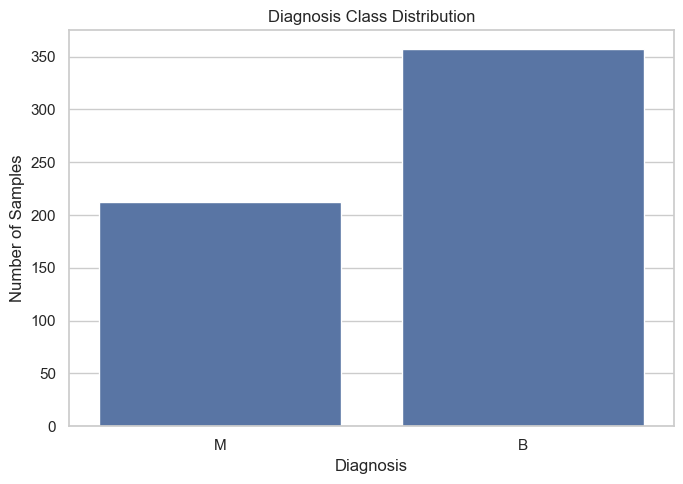

In [5]:
print("Class counts:")
display(data["Diagnosis"].value_counts())

print("\nClass proportions:")
display(data["Diagnosis"].value_counts(normalize=True).round(3))

plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="Diagnosis")
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

In [6]:
model_data = data.drop(columns=["ID"]).copy()

model_data["Diagnosis"] = model_data["Diagnosis"].map(
    {"B": 0, "M": 1}
)

if model_data["Diagnosis"].isnull().any():
    raise ValueError("Unexpected diagnosis labels were found.")

X = model_data.drop(columns=["Diagnosis"])
y = model_data["Diagnosis"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", X.shape[1])

print("\nFeature columns:")
print(X.columns.tolist())

print("\nEncoded target labels:")
display(y.value_counts().sort_index())

Feature matrix shape: (569, 30)
Target shape: (569,)
Number of features: 30

Feature columns:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']

Encoded target labels:


Diagnosis
0    357
1    212
Name: count, dtype: int64

## 6. Train, Validation, and Test Split

Split the data into:
- 400 training samples
- 100 validation samples
- 69 test samples

Stratification preserves the class proportions across the splits.
The validation set is used to assess the baseline model during
experimentation. The test set is kept separate for final evaluation.

In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    train_size=400,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=69,
    random_state=RANDOM_STATE,
    stratify=y_temp,
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

print("\nTraining label distribution:")
display(y_train.value_counts().sort_index())

print("\nValidation label distribution:")
display(y_val.value_counts().sort_index())

print("\nTest label distribution:")
display(y_test.value_counts().sort_index())

Training set: (400, 30) (400,)
Validation set: (100, 30) (100,)
Test set: (69, 30) (69,)

Training label distribution:


Diagnosis
0    251
1    149
Name: count, dtype: int64


Validation label distribution:


Diagnosis
0    63
1    37
Name: count, dtype: int64


Test label distribution:


Diagnosis
0    43
1    26
Name: count, dtype: int64

## 7. Feature Inspection

Inspect descriptive statistics and verify that the feature values are
numeric and finite.

No scaling is fitted at this stage. Any learned preprocessing will be
fitted only on the training set through a scikit-learn Pipeline.

In [8]:
print("Training feature summary:")
display(X_train.describe().T)

print("All features numeric:", all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in X_train.dtypes
))

print("All training values finite:", np.isfinite(X_train.to_numpy()).all())
print("Missing values in features:", X.isnull().sum().sum())

Training feature summary:


,count,mean,std,min,25%,50%,75%,max
radius_mean,400.0,14.132995,3.547547,6.981000,11.677500,13.385000,15.892500,28.11000
texture_mean,400.0,19.428750,4.314436,9.710000,16.330000,18.985000,21.847500,39.28000
perimeter_mean,400.0,91.956725,24.416626,43.790000,75.022500,86.545000,104.400000,188.50000
area_mean,400.0,655.758000,353.056120,143.500000,416.950000,551.400000,794.350000,2499.00000
smoothness_mean,400.0,0.095922,0.014411,0.062510,0.085102,0.095200,0.104900,0.16340
compactness_mean,400.0,0.102971,0.053717,0.019380,0.062820,0.091395,0.129650,0.34540
concavity_mean,400.0,0.088747,0.081261,0.000000,0.029540,0.059640,0.132150,0.42680
concave_points_mean,400.0,0.048737,0.039494,0.000000,0.019678,0.033375,0.071330,0.20120
symmetry_mean,400.0,0.181645,0.027747,0.106000,0.162625,0.179800,0.195300,0.30400
fractal_dimension_mean,400.0,0.062663,0.007142,0.050240,0.057495,0.061280,0.066165,0.09744


All features numeric: True
All training values finite: True
Missing values in features: 0


## 8. Baseline Model and Preprocessing

Logistic Regression is selected as the baseline classifier.

StandardScaler is placed inside a scikit-learn Pipeline so that:
- The scaler is fitted only on the training data.
- Validation and test data are transformed using the training statistics.
- The preprocessing and classifier can later be saved together.

This prevents data leakage from the validation and test sets.

In [10]:
baseline_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

baseline_model.fit(X_train, y_train)

print("Baseline model training completed.")
print("Training feature shape:", X_train.shape)
print("Number of features used:", baseline_model.n_features_in_)

Baseline model training completed.
Training feature shape: (400, 30)
Number of features used: 30


## 9. Validation Evaluation

Evaluate the baseline model on the validation set using accuracy,
precision, recall, and F1-score.

The validation results provide an initial assessment before the final
test evaluation.

In [11]:
y_val_pred = baseline_model.predict(X_val)

validation_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred, zero_division=0),
    "F1-Score": f1_score(y_val, y_val_pred, zero_division=0),
}

print("Validation Metrics:")
for metric_name, metric_value in validation_metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")

print("\nValidation Classification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1],
        target_names=["Benign (B)", "Malignant (M)"],
        zero_division=0,
    )
)

Validation Metrics:
Accuracy: 0.9600
Precision: 0.9714
Recall: 0.9189
F1-Score: 0.9444

Validation Classification Report:
               precision    recall  f1-score   support

   Benign (B)       0.95      0.98      0.97        63
Malignant (M)       0.97      0.92      0.94        37

     accuracy                           0.96       100
    macro avg       0.96      0.95      0.96       100
 weighted avg       0.96      0.96      0.96       100



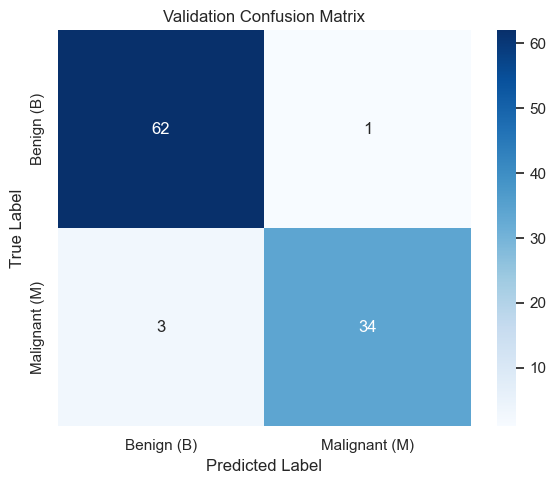

In [12]:
val_cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    val_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign (B)", "Malignant (M)"],
    yticklabels=["Benign (B)", "Malignant (M)"],
)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

## 10. Sample Prediction

Use one held-out validation sample to verify that the pipeline can
generate a prediction and class probabilities.

The prediction is compared with the actual label to confirm that the
output format and label mapping are correct.

In [14]:
sample = X_val.iloc[[0]]

actual_label = int(y_val.iloc[0])
predicted_label = int(baseline_model.predict(sample)[0])

class_names = {
    0: "Benign (B)",
    1: "Malignant (M)",
}

predicted_probabilities = baseline_model.predict_proba(sample)[0]

print("Sample feature shape:", sample.shape)
print("Actual diagnosis:", class_names[actual_label])
print("Predicted diagnosis:", class_names[predicted_label])
print("Prediction correct:", actual_label == predicted_label)

print("\nClass probabilities:")
for class_id, probability in enumerate(predicted_probabilities):
    print(f"{class_names[class_id]}: {probability:.4f}")

Sample feature shape: (1, 30)
Actual diagnosis: Malignant (M)
Predicted diagnosis: Malignant (M)
Prediction correct: True

Class probabilities:
Benign (B): 0.0059
Malignant (M): 0.9941


## 11. Final Test Evaluation

After evaluating the baseline on the validation set, evaluate it on the
held-out test set.

The test set is used only for this final evaluation, not for selecting
the model or tuning its parameters.

Final Test Metrics:
Accuracy: 0.9855
Precision: 1.0000
Recall: 0.9615
F1-Score: 0.9804

Test Classification Report:
               precision    recall  f1-score   support

   Benign (B)       0.98      1.00      0.99        43
Malignant (M)       1.00      0.96      0.98        26

     accuracy                           0.99        69
    macro avg       0.99      0.98      0.98        69
 weighted avg       0.99      0.99      0.99        69



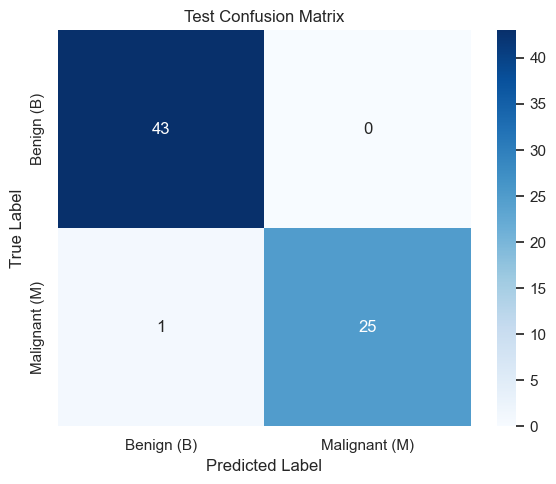

In [15]:
y_test_pred = baseline_model.predict(X_test)

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_test_pred, zero_division=0),
}

print("Final Test Metrics:")
for metric_name, metric_value in test_metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")

print("\nTest Classification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Benign (B)", "Malignant (M)"],
        zero_division=0,
    )
)

test_cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign (B)", "Malignant (M)"],
    yticklabels=["Benign (B)", "Malignant (M)"],
)

plt.title("Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [16]:
assert X_train.shape == (400, 30)
assert X_val.shape == (100, 30)
assert X_test.shape == (69, 30)

assert not X_train.isnull().values.any()
assert not X_val.isnull().values.any()
assert not X_test.isnull().values.any()

assert set(y_train.unique()).issubset({0, 1})
assert set(y_val.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

assert len(y_train) == len(X_train)
assert len(y_val) == len(X_val)
assert len(y_test) == len(X_test)

print("All dataset and split validation checks passed.")
print("The baseline pipeline can fit, evaluate, and predict successfully.")

All dataset and split validation checks passed.
The baseline pipeline can fit, evaluate, and predict successfully.


## 12. Experiment Summary

In this notebook, the Breast Cancer Wisconsin Diagnostic dataset was
loaded and inspected. Missing values, feature names, data dimensions,
and class distribution were checked.

The dataset was divided into training, validation, and test sets.
Logistic Regression was used as the baseline classifier, with
StandardScaler included in a scikit-learn Pipeline to prevent data
leakage.

The model was evaluated using accuracy, precision, recall, F1-score,
and confusion matrices. A sample prediction was also checked.

The notebook serves as the experimentation record. The next stage is
to refactor the validated workflow into reusable Python modules and
build an application that can save a fitted pipeline, reload it, and
make predictions without retraining.